# MolE embeddings

- This notebook generates embeddings across several datasets using the **MolE** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [ ]:
import mole
from mole import mole_predict
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from rdkit import DataStructs
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
import numpy as np
import numpy as np
from tqdm.auto import tqdm
import os
import mole

from hydra import compose, initialize_config_dir
from hydra.utils import instantiate


## File paths

Edit the following paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''
CHKPT_PATH   = ''

# Model set-up

In [ ]:
config_path = os.path.join(
    mole.__path__[0],
    "training",
    "configs",
)

overrides = [
    "model=finetune",
    "dropout=null",
    f"CHKPT_PATH='{CHKPT_PATH}'",
    "model.hyperparameters.pl_module._target_=mole.training.models.Encoder",
    "model.hyperparameters.pl_module.model._target_=mole.training.models.encoder",
]

with initialize_config_dir(
    version_base="1.2",
    config_dir=config_path,
):
    cfg = compose(
        config_name="base_config",
        overrides=overrides,
    )

mole_wrapper = instantiate(cfg.model.hyperparameters.pl_module)

In [4]:
total_params = sum(
    p.numel() for p in mole_wrapper.parameters()
)

trainable_params = sum(
    p.numel()
    for p in mole_wrapper.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters:     {total_params / 1e6:.2f}M")

Total parameters:     85,909,249
Trainable parameters: 85,909,249
Total parameters:     85.91M


# MCES

In [ ]:
distances = np.load(MCES_PATH)
mces      = distances['mces']
smiles    = distances['smiles']

print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


In [9]:
embeddings = mole_predict.encode(smiles=smiles, 
                                 pretrained_model='MolE_GuacaMol_27113.ckpt', 
                                 batch_size=256, 
                                 num_workers=8,
                                 accelerator='cpu')

[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not removing hydrogen atom without neighbors
[23:24:59] WARNING: not r

In [2]:
embeddings = np.load('MCES/MolE MCES embeddings.npy')

In [ ]:
# Save cosine similarities in a flattened row-major, upper triangle format.

X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MCES/MolE MCES pairwise cosine.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

100%|██████████| 64/64 [03:03<00:00,  2.87s/it]


Expected length: 2012094766
Written length: 2012094766


In [ ]:
# Save indices in a flattened row-major, upper triangle format.

n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MCES/MolE pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

100%|██████████| 63436/63436 [00:15<00:00, 4051.27it/s] 


Expected: 2012094766
Written: 2012094766


# MCES figure example

Cosine similarity: [[0.9542713]]


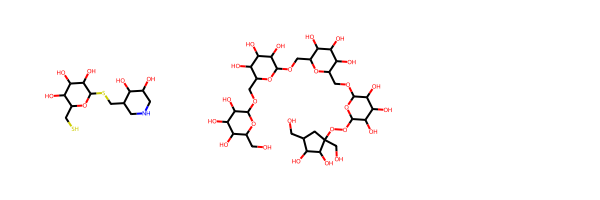

In [11]:
close_pair_a = "C1C(C(C(CN1)O)O)CSC2C(C(C(C(O2)CS)O)O)O"
close_pair_b = "C1C(C(C(C1(CO)OOC2C(C(C(C(O2)OCC3C(C(C(C(O3)COC4C(C(C(C(O4)COC5C(C(C(C(O5)CO)O)O)O)O)O)O)O)O)O)O)O)O)O)O)CO"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

embeddings = mole_predict.encode(smiles=[close_pair_a, close_pair_b], 
                                 pretrained_model='MolE_GuacaMol_27113.ckpt', 
                                 batch_size=256, 
                                 num_workers=8,
                                 accelerator='cpu')
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

Cosine similarity: [[0.06686649]]


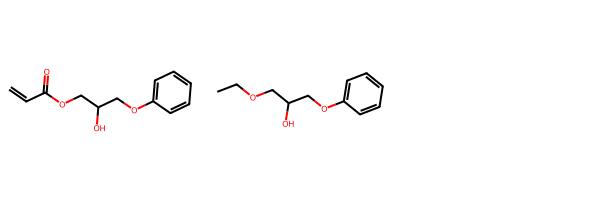

In [12]:
distant_pair_a = "C=CC(=O)OCC(COC1=CC=CC=C1)O"
distant_pair_b = "CCOCC(COC1=CC=CC=C1)O"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

embeddings = mole_predict.encode(smiles=[distant_pair_a, distant_pair_b], 
                                 pretrained_model='MolE_GuacaMol_27113.ckpt', 
                                 batch_size=256, 
                                 num_workers=8,
                                 accelerator='cpu')
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])

# Biogen

In [ ]:
biogen = pd.read_csv(BIOGEN_PATH)
smiles = biogen['SMILES'].tolist()

In [4]:
embeddings = mole_predict.encode(smiles=smiles, 
                                 pretrained_model='MolE_GuacaMol_27113.ckpt', 
                                 batch_size=32, 
                                 num_workers=4,
                                 accelerator='cpu')

In [6]:
np.save('Biogen/MolE Biogen embeddings.npy', embeddings)

# ZINC

In [ ]:
# ZINC file contains randomly sampled molecules. 
data   = pd.read_csv(ZINC30K_PATH)[:30000]
smiles = data['SMILES'].tolist()

In [4]:
embeddings = mole_predict.encode(smiles=smiles, 
                                 pretrained_model='MolE_GuacaMol_27113.ckpt', 
                                 batch_size=256, 
                                 num_workers=4,
                                 accelerator='cpu')

In [ ]:
np.save('ZINC/MolE ZINC30K embeddings.npy', embeddings)